# Anti-spoofing model: training and testing

This notebook trains a model that tells a **real face** from a **fake** (a printed photo or a phone screen), tests it, and saves it as `antispoof_ours.onnx` for the attendance app.

**How to use it**

1. **Runtime → Change runtime type → T4 GPU → Save.**
2. In the first code cell, paste your Kaggle dataset name into `KAGGLE_DATASET`.
3. **Runtime → Run all.** It stops twice to ask you something: once to connect Google Drive (allow it) and once to paste your Kaggle API token.
4. Training takes about 30–60 minutes. Everything you need for the report is printed in the last cell and saved to the `antispoof` folder in your Google Drive.

Don't change the image size (128), the label order (real = 0, spoof = 1) or the export cell: the app expects exactly that.

## 0. Settings

In [1]:
# From the dataset's Kaggle page: Download menu -> "Copy API command".
# It looks like  kaggle datasets download -d someone/lcc-fasd  -- paste only the someone/lcc-fasd part.
KAGGLE_DATASET = "aleksandrpikul222/lcc-fasd"

EPOCHS = 6        # passes over the training images; 6 is plenty to fine-tune
BATCH_SIZE = 64   # lower to 32 if you get "CUDA out of memory"
SIZE = 128        # the app sends 128x128 faces: do not change

ROOT = '/content/data'                          # where the dataset is unzipped
SAVE_DIR = '/content/drive/MyDrive/antispoof/'  # results, saved in your Google Drive

assert KAGGLE_DATASET != "OWNER/DATASET", "Paste your Kaggle dataset name into KAGGLE_DATASET first"

## 1. GPU, libraries and Google Drive
Allow the Google Drive pop-up: the model is saved there so it survives if Colab disconnects.

In [2]:
import torch
print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available()
      else 'NONE - Runtime > Change runtime type > T4 GPU, then Run all again')

!pip -q install kaggle onnx onnxscript onnxruntime

from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs(SAVE_DIR, exist_ok=True)

GPU: Tesla T4
Mounted at /content/drive


## 2. Kaggle key
Kaggle now gives a token (a long text starting with `KGAT_`) instead of a `kaggle.json` file. Kaggle -> Settings -> API -> Generate New Token, copy it, and paste it into the box when asked. It is not saved in this notebook.

In [3]:
import os
from getpass import getpass

if not os.environ.get('KAGGLE_API_TOKEN') and not os.path.exists(os.path.expanduser('~/.kaggle/kaggle.json')):
    os.environ['KAGGLE_API_TOKEN'] = getpass('Paste your Kaggle API token and press Enter: ').strip()
print('Kaggle key ready')

Paste your Kaggle API token and press Enter: ··········
Kaggle key ready


## 3. Download the dataset
Skipped if it's already downloaded. The folder list at the end should show names with `real` and `spoof` (or `live` / `fake`) in them.

In [4]:
import os
if not os.path.isdir(ROOT) or not os.listdir(ROOT):
    !kaggle datasets download -d {KAGGLE_DATASET} -p {ROOT} --unzip
!find {ROOT} -maxdepth 3 -type d | head -40

Dataset URL: https://www.kaggle.com/datasets/aleksandrpikul222/lcc-fasd
License(s): apache-2.0
100% 4.84G/4.84G [04:20<00:00, 19.9MB/s]

/content/data
/content/data/LCC_FASD


## 4. Find the images and their labels
Labels come from folder names; train / validation / test from the dataset's own split folders, or a random 80/10/10 split if it has none.

**Check the printout:** each split should have both real and spoof images. If one shows 0 or only one label, send Bilquees the folder list from step 3.

In [7]:
from pathlib import Path
import random, collections

ROOT = Path(ROOT)

# This dataset keeps every image in ONE folder and lists them in four text files:
#   CLIENT_*   = real faces (label 0)      IMPOSTER_* = fakes / spoofs (label 1)
#   *_TRAIN / *_TEST = which images are for training and which for testing
def read_list(name, label):
    found = list(ROOT.rglob(name))
    assert found, f'{name} not found: send the folder list from step 3 to Bilquees'
    folder = found[0].parent
    items = []
    for line in found[0].read_text().splitlines():
        line = line.strip()
        if line:
            path = folder / Path(line).name  # keep only the file name: the folder in the file is Kaggle's
            if path.exists():
                items.append((path, label))
    print(f'{name:18} {len(items)} images')
    return items

splits = {
    'train': read_list('CLIENT_TRAIN.txt', 0) + read_list('IMPOSTER_TRAIN.txt', 1),
    'test': read_list('CLIENT_TEST.txt', 0) + read_list('IMPOSTER_TEST.txt', 1),
}

# there is no validation list: take 10% of the training images for validation
random.seed(0)
random.shuffle(splits['train'])
cut = len(splits['train']) // 10
splits['val'], splits['train'] = splits['train'][:cut], splits['train'][cut:]

for k, v in splits.items():
    print(f'{k:5}', len(v), 'images', dict(collections.Counter('spoof' if y else 'real' for _, y in v)))
    assert {0, 1} <= {y for _, y in v}, f'the {k} split needs both real and spoof images'

CLIENT_TRAIN.txt   1553 images
IMPOSTER_TRAIN.txt 13508 images
CLIENT_TEST.txt    389 images
IMPOSTER_TEST.txt  3377 images
train 13555 images {'spoof': 12166, 'real': 1389}
test  3766 images {'real': 389, 'spoof': 3377}
val   1506 images {'spoof': 1342, 'real': 164}


## 5. The model
MobileNetV2, pretrained on ImageNet, with its last layer replaced by two outputs: `[real, spoof]`.

In [8]:
import numpy as np, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from PIL import Image, ImageFile

ImageFile.LOAD_TRUNCATED_IMAGES = True  # a few dataset images are cut short; load what's there
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

train_tf = transforms.Compose([
    transforms.Resize((SIZE, SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3, 0.3, 0.2),  # different lighting
    transforms.ToTensor(),                  # pixels 0..1, like the app sends
])
test_tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor()])

class Faces(Dataset):
    def __init__(self, items, tf):
        self.items, self.tf = items, tf
    def __len__(self):
        return len(self.items)
    def __getitem__(self, i):
        path, y = self.items[i]
        return self.tf(Image.open(path).convert('RGB')), y

class Net(nn.Module):
    """MobileNetV2 with ImageNet normalisation built in, so the app can send 0..1 pixels."""
    def __init__(self):
        super().__init__()
        self.body = models.mobilenet_v2(weights='IMAGENET1K_V1')
        self.body.classifier[1] = nn.Linear(self.body.last_channel, 2)  # [real, spoof]
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x):
        return self.body((x - self.mean) / self.std)

loaders = {
    k: DataLoader(Faces(v, train_tf if k == 'train' else test_tf),
                  batch_size=BATCH_SIZE, shuffle=(k == 'train'), num_workers=2)
    for k, v in splits.items()
}

def evaluate(model, loader, threshold=0.0):
    """APCER = fakes accepted as real; BPCER = real faces refused; ACER = their average."""
    model.eval()
    ys, ds = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(dev))
            ds += (out[:, 0] - out[:, 1]).cpu().tolist()  # real minus spoof, like the app
            ys += y.tolist()
    ys, ds = np.array(ys), np.array(ds)
    accepted = ds >= threshold
    apcer = accepted[ys == 1].mean()
    bpcer = (~accepted[ys == 0]).mean()
    return apcer, bpcer, (apcer + bpcer) / 2

## 6. Train
About 5–10 minutes per epoch on a T4. After each epoch it scores the validation images and keeps the best model in Drive. The loss should fall from about 0.7 towards 0.1.

If Colab disconnects: **Runtime → Run all** again. The dataset and the best model so far are kept, and training starts over from that best model.

In [9]:
SAVE = SAVE_DIR + 'best.pt'
model = Net().to(dev)
if os.path.exists(SAVE):
    model.load_state_dict(torch.load(SAVE, map_location=dev))
    print('Continuing from the best model saved earlier')

counts = collections.Counter(y for _, y in splits['train'])
weights = torch.tensor([1 / counts[0], 1 / counts[1]], dtype=torch.float)
weights = (weights / weights.sum() * 2).to(dev)  # datasets have far more spoofs: balance them
loss_fn = nn.CrossEntropyLoss(weight=weights)
opt = torch.optim.AdamW(model.parameters(), lr=3e-4)

best = evaluate(model, loaders['val'])[2] if os.path.exists(SAVE) else 1.0
history = []
for epoch in range(EPOCHS):
    model.train()
    for i, (x, y) in enumerate(loaders['train']):
        opt.zero_grad()
        loss = loss_fn(model(x.to(dev)), y.to(dev))
        loss.backward()
        opt.step()
        if i % 100 == 0:
            print(f'epoch {epoch + 1} step {i} loss {loss.item():.3f}')
    apcer, bpcer, acer = evaluate(model, loaders['val'])
    history.append({'epoch': epoch + 1, 'loss': round(loss.item(), 4),
                    'val_apcer': apcer, 'val_bpcer': bpcer, 'val_acer': acer})
    print(f'epoch {epoch + 1}: val APCER {apcer:.2%}  BPCER {bpcer:.2%}  ACER {acer:.2%}')
    if acer < best:
        best = acer
        torch.save(model.state_dict(), SAVE)
        print('  saved as best')
if not os.path.exists(SAVE):  # no epoch beat 100% ACER: save the last one anyway
    torch.save(model.state_dict(), SAVE)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 118MB/s]


epoch 1 step 0 loss 0.699
epoch 1 step 100 loss 0.068
epoch 1 step 200 loss 0.131
epoch 1: val APCER 7.23%  BPCER 0.00%  ACER 3.61%
  saved as best
epoch 2 step 0 loss 0.057
epoch 2 step 100 loss 0.020
epoch 2 step 200 loss 0.009
epoch 2: val APCER 0.97%  BPCER 2.44%  ACER 1.70%
  saved as best
epoch 3 step 0 loss 0.051
epoch 3 step 100 loss 0.049
epoch 3 step 200 loss 0.116
epoch 3: val APCER 0.37%  BPCER 0.61%  ACER 0.49%
  saved as best
epoch 4 step 0 loss 0.019
epoch 4 step 100 loss 0.033
epoch 4 step 200 loss 0.033
epoch 4: val APCER 0.89%  BPCER 1.83%  ACER 1.36%
epoch 5 step 0 loss 0.075
epoch 5 step 100 loss 0.022
epoch 5 step 200 loss 0.028
epoch 5: val APCER 0.15%  BPCER 2.44%  ACER 1.29%
epoch 6 step 0 loss 0.017
epoch 6 step 100 loss 0.033
epoch 6 step 200 loss 0.026
epoch 6: val APCER 0.30%  BPCER 1.83%  ACER 1.06%


## 7. Score on the test images
The test images were never used for training or for picking the best epoch, so this is the honest score.

In [10]:
model = Net().to(dev)
model.load_state_dict(torch.load(SAVE, map_location=dev))
test_apcer, test_bpcer, test_acer = evaluate(model, loaders['test'])
print(f'TEST  APCER {test_apcer:.2%}  BPCER {test_bpcer:.2%}  ACER {test_acer:.2%}')

TEST  APCER 5.57%  BPCER 8.74%  ACER 7.15%


## 8. Export for the app
Saves `antispoof_ours.onnx` to Drive and checks that it gives the same answers as the PyTorch model. The two printed rows must match to about 3 decimal places.

In [11]:
model.eval().cpu()
OUT = SAVE_DIR + 'antispoof_ours.onnx'
try:
    torch.onnx.export(model, torch.zeros(1, 3, SIZE, SIZE), OUT, input_names=['input'],
                      output_names=['logits'], opset_version=17, dynamo=False)
except TypeError:  # older PyTorch has no dynamo option
    torch.onnx.export(model, torch.zeros(1, 3, SIZE, SIZE), OUT, input_names=['input'],
                      output_names=['logits'], opset_version=17)

import onnxruntime as ort
x = torch.rand(1, 3, SIZE, SIZE)
with torch.no_grad():
    print(model(x).numpy())
print(ort.InferenceSession(OUT).run(None, {'input': x.numpy()})[0])
print('saved', OUT)

/tmp/ipykernel_735/671488017.py:4: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(model, torch.zeros(1, 3, SIZE, SIZE), OUT, input_names=['input'],


[[-1.0248226  1.3649008]]
[[-1.024822   1.3649004]]
saved /content/drive/MyDrive/antispoof/antispoof_ours.onnx


## 9. Compare with the app's current model
Downloads the app's current anti-spoofing model (facenox) from the project's GitHub and scores both on up to 3,000 test images, preparing each image the way the app does.

In [12]:
import urllib.request, cv2
CURRENT = SAVE_DIR + 'antispoof_current.onnx'
if not os.path.exists(CURRENT):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/b1lquees/'
                               'FaceRecognition-AttendanceSystem/main/attendance/models/antispoof.onnx',
                               CURRENT)

random.seed(0)
test_items = random.sample(splits['test'], min(3000, len(splits['test'])))
ys = np.array([y for _, y in test_items])
print(len(test_items), 'images:', (ys == 0).sum(), 'real,', (ys == 1).sum(), 'spoof')

def onnx_scores(model_path, items):
    session = ort.InferenceSession(model_path)
    name = session.get_inputs()[0].name
    out = []
    for path, _ in items:
        rgb = np.array(Image.open(path).convert('RGB'))
        x = cv2.resize(rgb, (SIZE, SIZE), interpolation=cv2.INTER_AREA)
        x = x.transpose(2, 0, 1)[None].astype(np.float32) / 255.0
        logits = session.run(None, {name: x})[0][0]
        out.append(logits[0] - logits[1])
    return np.array(out)

def rates(ds, threshold=0.0):
    accepted = ds >= threshold
    apcer = accepted[ys == 1].mean()      # fakes let in
    bpcer = (~accepted[ys == 0]).mean()   # real faces refused
    return apcer, bpcer, (apcer + bpcer) / 2

results = {'current (facenox)': onnx_scores(CURRENT, test_items),
           'ours (MobileNetV2)': onnx_scores(OUT, test_items)}
for name, ds in results.items():
    a, b, c = rates(ds)
    print(f'{name:20} APCER {a:.1%}  BPCER {b:.1%}  ACER {c:.1%}')

3000 images: 303 real, 2697 spoof
current (facenox)    APCER 48.0%  BPCER 7.3%  ACER 27.6%
ours (MobileNetV2)   APCER 11.7%  BPCER 3.3%  ACER 7.5%


## 10. Thresholds and confusion matrix
A higher threshold lets in fewer fakes but refuses more real faces. The threshold with the lowest ACER is the one to give Bilquees for `LIVENESS_THRESHOLD`.

threshold -2: APCER 19.2%  BPCER 1.3%  ACER 10.3%
threshold -1: APCER 14.9%  BPCER 2.3%  ACER 8.6%
threshold +0: APCER 11.7%  BPCER 3.3%  ACER 7.5%
threshold +1: APCER 8.4%  BPCER 5.6%  ACER 7.0%
threshold +2: APCER 5.3%  BPCER 10.6%  ACER 7.9%
threshold +3: APCER 3.3%  BPCER 12.5%  ACER 7.9%


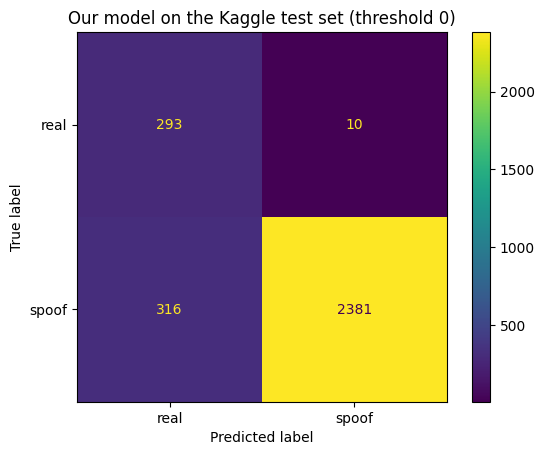

In [13]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ds = results['ours (MobileNetV2)']
thresholds = {}
for t in [-2, -1, 0, 1, 2, 3]:
    thresholds[t] = rates(ds, t)
    a, b, c = thresholds[t]
    print(f'threshold {t:+}: APCER {a:.1%}  BPCER {b:.1%}  ACER {c:.1%}')
best_threshold = min(thresholds, key=lambda t: thresholds[t][2])

ConfusionMatrixDisplay.from_predictions(ys, np.where(ds >= 0, 0, 1), display_labels=['real', 'spoof'])
plt.title('Our model on the Kaggle test set (threshold 0)')
plt.savefig(SAVE_DIR + 'confusion_ours.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Results for the report
Copy this into the report. It's also saved as `results.json` in the Drive `antispoof` folder. Then share `antispoof_ours.onnx`, `confusion_ours.png` and `results.json` with Bilquees.

In [14]:
import json
summary = {
    'dataset': KAGGLE_DATASET,
    'images': {k: dict(collections.Counter('spoof' if y else 'real' for _, y in v))
               for k, v in splits.items()},
    'epochs': history,
    'test_kaggle': {'apcer': test_apcer, 'bpcer': test_bpcer, 'acer': test_acer},
    'comparison_threshold_0': {name: dict(zip(['apcer', 'bpcer', 'acer'], rates(d)))
                               for name, d in results.items()},
    'best_threshold': best_threshold,
}
with open(SAVE_DIR + 'results.json', 'w') as f:
    json.dump(summary, f, indent=2, default=float)

print(f'Dataset: {KAGGLE_DATASET}')
for k, v in summary['images'].items():
    print(f'  {k:5} {v}')
print(f'\nTest set (our model): APCER {test_apcer:.1%}  BPCER {test_bpcer:.1%}  ACER {test_acer:.1%}')
print('\n| Model | APCER | BPCER | ACER |\n| --- | --- | --- | --- |')
for name, d in results.items():
    a, b, c = rates(d)
    print(f'| {name} | {a:.1%} | {b:.1%} | {c:.1%} |')
print(f'\nBest threshold for the app (LIVENESS_THRESHOLD): {best_threshold}')

Dataset: aleksandrpikul222/lcc-fasd
  train {'spoof': 12166, 'real': 1389}
  test  {'real': 389, 'spoof': 3377}
  val   {'spoof': 1342, 'real': 164}

Test set (our model): APCER 5.6%  BPCER 8.7%  ACER 7.2%

| Model | APCER | BPCER | ACER |
| --- | --- | --- | --- |
| current (facenox) | 48.0% | 7.3% | 27.6% |
| ours (MobileNetV2) | 11.7% | 3.3% | 7.5% |

Best threshold for the app (LIVENESS_THRESHOLD): 1


In [6]:
import os, glob

# folders and a few file names in each
for folder, subfolders, files in os.walk(str(ROOT)):
    depth = folder[len(str(ROOT)):].count(os.sep)
    if depth <= 3:
        print(folder, '->', len(files), 'files', files[:3])

# the first lines of any text files
for f in glob.glob(str(ROOT) + '/**/*.txt', recursive=True)[:5]:
    print('=====', f)
    print(open(f).read()[:300])

/content/data -> 0 files []
/content/data/LCC_FASD -> 18831 files ['spoof_4360.png', 'spoof_755.png', 'YOUTUBE_IIYAMAXU_SMG955U_S0_id43_s0_204.png']
===== /content/data/LCC_FASD/CLIENT_TEST.txt
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_id43_s0_105.png
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_id43_s0_124.png
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_id43_s0_139.png
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_id43_s0_154.png
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_id43_s1_15.png
/kaggle/input/lcc-fas
===== /content/data/LCC_FASD/IMPOSTER_TRAIN.txt
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_VX2363SMHL_LGL90_id47_s2_15.png
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_VX2363SMHL_LGL90_id47_s2_30.png
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_VX2363SMHL_LGL90_id47_s2_45.png
/kaggle/input/lcc-fasd/LCC_FASD/YOUTUBE_VX2363SMHL_LGL90_id47_s2_60.png
/kaggle/inpu
===== /content/data/LCC_FASD/IMPOSTER_TEST.txt
/kaggle/input/lcc-fasd/LCC_FASD/spoof_1793.png
/kaggle/input/lcc-fasd/LCC_FASD/spoof_1794.png
/kaggle/input/l